In [1]:
import numpy as np
import matplotlib.pyplot as plt
import all_functions as funcs
import os
import pickle
import scipy.io

In [2]:
network_params = {"realizations": 200  #(200 originally) small scale realizations  (Critical : should be a large value if large number APs and UEs are used)
                    , "delta_h": 10 # height difference
                    , "area": 100  # lxl Service Area
                    , "bandwidth": 100e6
                    , "L": 4  # APs
                    , "N": 2  # antennas per AP
                    , "K": 3  # UEs
                    , "tau_c": 200 # total samples in coherence block
                    , "tau_p": 1  # samples for pilots
                    , "p_k": 200  # uplink max power (mW)
                    , "uplink_variance_dbm": -94 # Receiver noise power (dBm)
                    , "carrier_frequency": 2000  # carrier frequency (MHz)
                    , "sigma_sf_los": 4  # Shadow fading LoS (dB)
                                     }

In [44]:
setups=1000
batch=network_params["realizations"]
v=-1
d = 0   #rician factor (0: no LoS component)

norm_type = np.inf

In [45]:
results_path=os.getcwd()+"/Results/"
if not os.path.exists(results_path):
    os.makedirs(results_path)
else:
    print(f"Folder already exists")

Folder already exists


In [50]:
K = network_params["K"]
SINR = np.zeros((K,setups))

np.random.seed(5)
p_max=network_params["p_k"]

# A network setup is generated, distances and spatial correlation matrices are calculated
R_spatial_corr_norm, B_channel_gain, HMean_norm, k_rician_factor = funcs.simulation_area(network_params)

# Cooperation clusters formation and pilot assignment
D_cellular, D_DCC, pilot_indicies = funcs.initial_access(network_params,B_channel_gain)

# for same network setup , k-factor for all channels is set equal to 0 and in next iteration to 5 to cover both cases.
k_rician_factor[:]=d

# Generate random channels, channel mean(los component) and spatial correlation matrix
H, HMean, R_spatial_corr = funcs.channel_generation(network_params, R_spatial_corr_norm,HMean_norm,k_rician_factor)

# Estimate channels using MMSE estimator  (CSI is obtained)
H_hat = funcs.channel_estimation(network_params, R_spatial_corr, pilot_indicies, H,
                                                    HMean, p_max)

#reshaping
H = np.moveaxis(H, -1, 0)
H_hat = np.moveaxis(H_hat, -1, 0)
H = np.swapaxes(H, 2, 3)
H_hat = np.swapaxes(H_hat, 2, 3)
K=network_params["K"]

for i in range(setups):
    p_inital = np.random.uniform(low=np.nextafter(0,1), high=np.nextafter(1,2), size=(K,1))     #draw random initial power for each user ]0,1]
    p_k = p_max / np.linalg.norm(p_inital, norm_type) * p_inital   # Kx1 power vector for all UEs (scaled such that power constraint fulfilled with equality)

    SINR[:,i][:,np.newaxis]= funcs.compute_SINR_MRC(network_params, p_k, D_DCC, H_hat, H)
    # print("Progress: ", i, "/",setups)

M, u, b, C, sigma = funcs.calculate_interf_matrix(network_params, D_DCC, H_hat, H)


In [51]:

A = 1/p_max * np.eye(K)
M_k = np.zeros((K,K,K))
for k in range(K):
    M_k[k,:,:] = M + u @ A[:,k][:,np.newaxis].T
    M_k_inv = np.linalg.inv(M_k[k,:,:])
    print("M_",k,": ",M_k[k,:,:],"\n")
    print("Inv: ", M_k_inv,"\n")
    print("Z-matrix? ", funcs.is_ZMatrix(M_k_inv),"\n")



M_ 0 :  [[1.01793029 0.10541313 0.01655424]
 [0.00522009 0.66096391 0.00675622]
 [0.14989153 0.07319598 0.95734543]] 

Inv:  [[ 0.98553041 -0.15541053 -0.01594484]
 [-0.006211    1.51510467 -0.01058506]
 [-0.15382957 -0.09150808  1.04786083]] 

Z-matrix?  True 

M_ 1 :  [[1.01789134 0.10545208 0.01655424]
 [0.00521406 0.66096993 0.00675622]
 [0.14973632 0.07335119 0.95734543]] 

Inv:  [[ 0.98556509 -0.15546895 -0.01594503]
 [-0.00620382  1.51509257 -0.0105851 ]
 [-0.15367476 -0.09176886  1.04785999]] 

Z-matrix?  True 

M_ 2 :  [[1.01789134 0.10541313 0.01659319]
 [0.00521406 0.66096391 0.00676225]
 [0.14973632 0.07319598 0.95750065]] 

Inv:  [[ 0.98557025 -0.15541276 -0.01598204]
 [-0.00620275  1.51510421 -0.01059277]
 [-0.15365174 -0.09151806  1.04769479]] 

Z-matrix?  True 



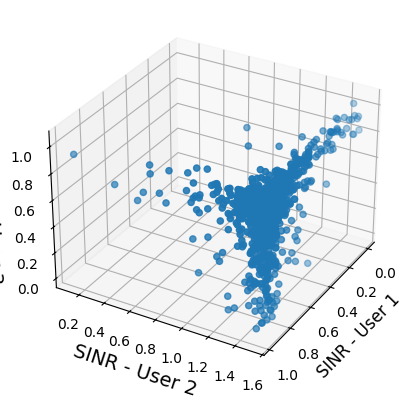

In [52]:
%matplotlib inline

x,y,z = SINR

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(x,y,z)

ax.set_xlabel("SINR - User 1", fontsize=12)
ax.set_ylabel("SINR - User 2", fontsize=14)
ax.set_zlabel("SINR - User 3", fontsize=14)
ax.view_init(elev=30, azim=30)  # Set elevation to 30° and azimuth to 45°

plt.show()

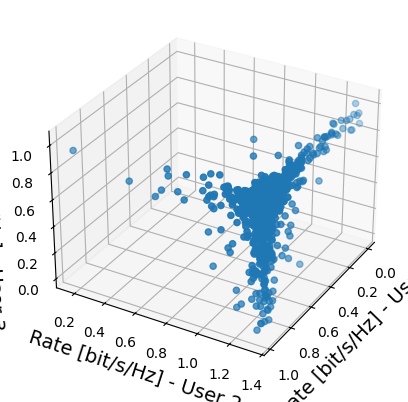

In [53]:
rate_x = np.log2(1+np.array(x) )
rate_y = np.log2(1+np.array(y) )
rate_z = np.log2(1+np.array(z) )
ax = plt.figure().add_subplot(projection='3d')
ax.scatter3D(rate_x, rate_y, rate_z)

ax.set_xlabel("Rate [bit/s/Hz] - User 1", fontsize=14)
ax.set_ylabel("Rate [bit/s/Hz] - User 2", fontsize=14)
ax.set_zlabel("Rate [bit/s/Hz] - User 3", fontsize=14)
ax.view_init(elev=30, azim=30)  # Set elevation to 30° and azimuth to 45°
